In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity=1

In [ ]:
name='Chen2020_Head-and-Neck-2'; cat='Head-and-Neck'
pth      = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth,'data')
pth_in   = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_feat = os.path.join(pth_data,'features','biomart')
pth_fig  = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
pth_cb   = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
# load manifold data
adata = sc.read_h5ad(os.path.join(pth_in,'manifold.h5ad')); print(adata.shape)

(3674, 22080)


In [ ]:
# build module dict from biomart gene sets (read hsapiens, drop NaN/dupes); union = control pool
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
gref = feat['union'][feat['union'].isin(adata.var_names)]
mods = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,nm in mods.items():
    g = feat[src][feat[src].isin(adata.var_names)]
    print(f'{nm}: {len(g)}/{len(feat[src])} genes detected')
    sc.tl.score_genes(adata, gene_list=g, score_name=nm, ctrl_as_ref=False, gene_pool=gref, random_state=1234)

Gast: 73/81 genes detected
pSom: 91/98 genes detected
Crest: 99/104 genes detected


In [ ]:
# --- Gate 2 evidence: is there a Gast/pSom hub diverging into two arms? ---
# module cross-correlations (branching wants Gast<->pSom co-vary or cross-repress; both oppose Crest)
o = adata.obs
for a,b in [('Gast','pSom'),('Gast','Crest'),('pSom','Crest')]:
    print(f'r({a},{b}) = {np.corrcoef(o[a],o[b])[0,1]:+.3f}')
# confounder check: is any module tracking proliferation?
cyc = o.cell_cycle_phase.isin(['G1/S','G2/M','Intermediate']).astype(float)
for m in ['Gast','pSom','Crest']:
    print(f'r({m}, cycling) = {np.corrcoef(o[m],cyc)[0,1]:+.3f}')

r(Gast,pSom) = -0.048
r(Gast,Crest) = -0.541
r(pSom,Crest) = -0.438
r(Gast, cycling) = -0.334
r(pSom, cycling) = +0.013
r(Crest, cycling) = +0.110


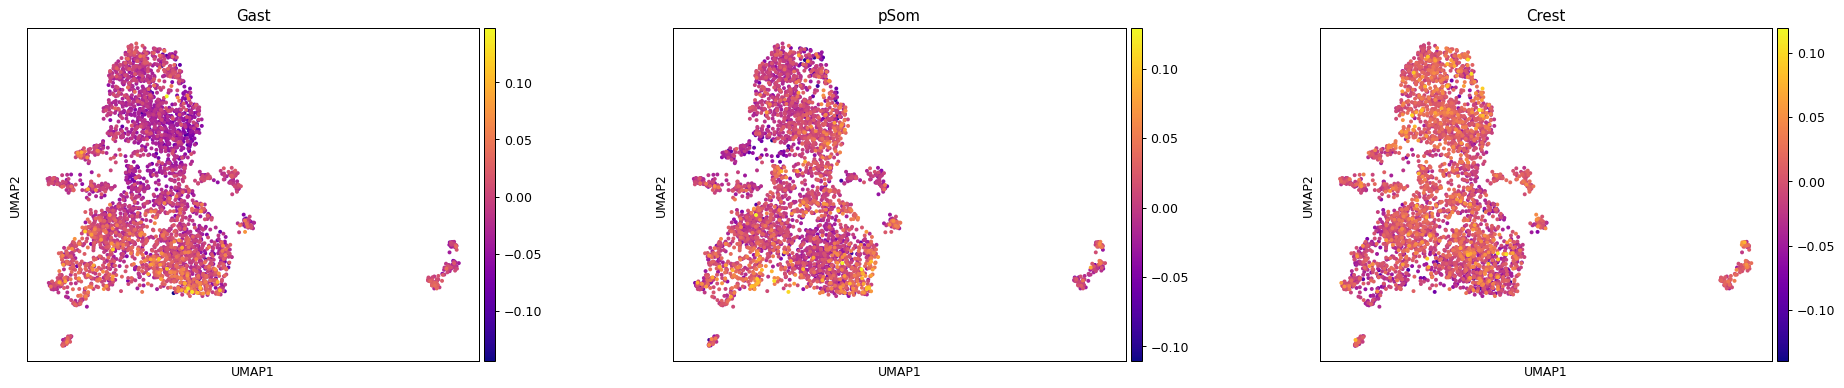

In [ ]:
# visual inspection -- the three signatures on the manifold
sc.pl.umap(adata, color=['Gast','pSom','Crest'], cmap='plasma', size=40, wspace=.3)

In [ ]:
# save signatures data
adata.write(os.path.join(pth_in,'signatures.h5ad'))

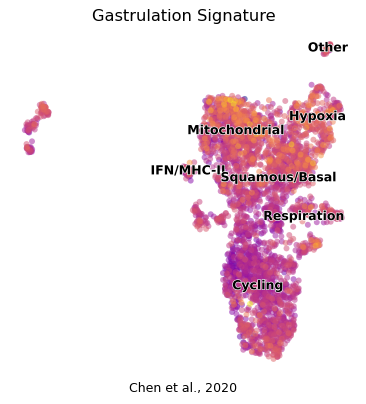

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(5,5))
sc.pl.umap(adata, color='Gast', cmap='plasma', alpha=.5, size=90, colorbar_loc=None, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=90, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Gastrulation Signature', size=13)
ax.text(.5,-.05,'Chen et al., 2020', ha='center', transform=ax.transAxes)
plt.savefig(os.path.join(pth_fig,'Gast_signature.pdf'), bbox_inches='tight'); plt.show()

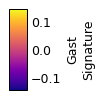

In [ ]:
fig = plt.figure(figsize=(.66,1)); cax = fig.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Gast\nSignature'); cb.solids.set_alpha(1)
plt.savefig(os.path.join(pth_cb,'Gast_colorbar.pdf'), bbox_inches='tight'); plt.show()

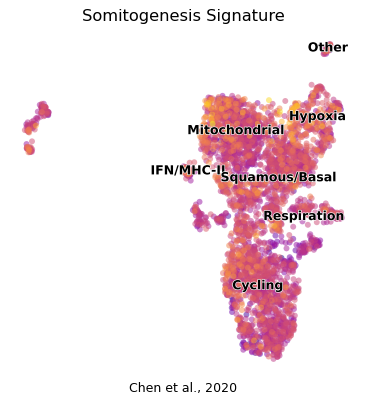

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(5,5))
sc.pl.umap(adata, color='pSom', cmap='plasma', alpha=.5, size=90, colorbar_loc=None, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=90, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Somitogenesis Signature', size=13)
ax.text(.5,-.05,'Chen et al., 2020', ha='center', transform=ax.transAxes)
plt.savefig(os.path.join(pth_fig,'pSom_signature.pdf'), bbox_inches='tight'); plt.show()

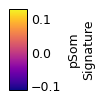

In [ ]:
fig = plt.figure(figsize=(.66,1)); cax = fig.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('pSom\nSignature'); cb.solids.set_alpha(1)
plt.savefig(os.path.join(pth_cb,'pSom_colorbar.pdf'), bbox_inches='tight'); plt.show()

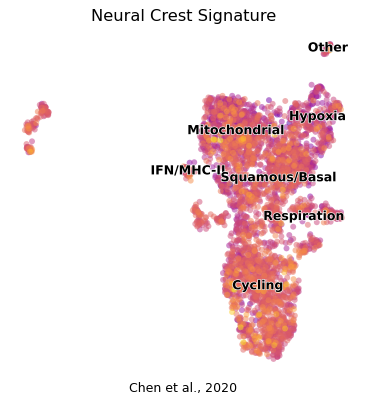

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(5,5))
sc.pl.umap(adata, color='Crest', cmap='plasma', alpha=.5, size=90, colorbar_loc=None, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=90, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Neural Crest Signature', size=13)
ax.text(.5,-.05,'Chen et al., 2020', ha='center', transform=ax.transAxes)
plt.savefig(os.path.join(pth_fig,'Crest_signature.pdf'), bbox_inches='tight'); plt.show()

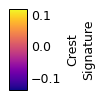

In [ ]:
fig = plt.figure(figsize=(.66,1)); cax = fig.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Crest\nSignature'); cb.solids.set_alpha(1)
plt.savefig(os.path.join(pth_cb,'Crest_colorbar.pdf'), bbox_inches='tight'); plt.show()